# Smile decomposition

Participants smile more when both partners' smiles are manipulated in the same direction (participant × other condition interaction, `R_scripts/mimicry.R`).
Here we look at what changes in the smile signal: which part of the distribution, how often people smile, and when in the interaction.

Two signals, from the participants' real (non-manipulated) face:
* **eyes** : py-feat AU06 (orbicularis oculi)
* **mouth** : MediaPipe smile (mouthSmileLeft + mouthSmileRight)

# Imports

In [1]:
#Data handling, plots and statistics
import polars as pl
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

# Late start
In real_2:2 p2p6, p2 joined at 95.6 s: p6 was alone before, so the face frames of both participants before 95.6 s are removed. All the frames of the other interactions are kept.

In [2]:
#Interaction where one participant joined late : (participant, partner, time the second participant joined in s)
late_starts = [("mkprolific_participant_real_22p2", "mkprolific_participant_real_22p6", 95.6)]
fps = 30


def remove_late_start(df):
    """
        Removes the face frames before both participants were there (late starts only).
    """
    keep = pd.Series(True, index=df.index)

    #Both participants of a late start, whichever is user_id or other_id
    for participant, partner, start_s in late_starts:
        pair = ((df["user_id"] == participant) & (df["other_id"] == partner)) | ((df["user_id"] == partner) & (df["other_id"] == participant))
        keep[pair & (df["frame"] < start_s * fps)] = False

    return df.loc[keep]

# Import data
py-feat has no frame column, so the frame is the row order within each recording. Recordings stored in several blocks of rows (uncertain frame order) are left out of the time course (none in the v3 data).

In [3]:
#Import eyes (py-feat)
key = ["sid", "user_id", "other_id", "participant_condition", "other_condition"]

eyes_df = pl.read_csv("../data/face_data/pyf_results/all_au_pf_v3.csv"
                          , columns=["", "sid", "user_id", "other_id", "participant_condition", "other_condition", "manipulated", "AU06"]
                          ).to_pandas()

eyes_df = eyes_df.rename({"": "row", "AU06": "smile"}, axis=1)

eyes_df = eyes_df.loc[eyes_df["manipulated"] == False]

eyes_df = eyes_df.dropna(subset=["other_id"])

#Frame number = position of the row within its recording (cumcount counts 0, 1, 2... inside each group)
eyes_df = eyes_df.sort_values("row")
eyes_df["frame"] = eyes_df.groupby(key).cumcount()
eyes_df["signal"] = "eyes"

#Recordings stored in several blocks of rows : a jump of more than 1 in the row number marks a new block
eyes_df["jump"] = eyes_df.groupby(key)["row"].diff() > 1
blocks_df = eyes_df.groupby(key)["jump"].sum().reset_index()
blocks_df["contiguous"] = blocks_df["jump"] == 0
blocks_df["signal"] = "eyes"

In [4]:
#Import mouth (MediaPipe)
mouth_df = pl.read_csv("../data/face_data/mediapipe_results/all_au_v3.csv"
                          , columns=["sid", "user_id", "other_id", "participant_condition", "other_condition", "manipulated", "frame", "mouthSmileRight", "mouthSmileLeft"]
                          , schema_overrides={"other_id": pl.Utf8, "participant_condition": pl.Utf8, "other_condition": pl.Utf8}
                          ).to_pandas()

mouth_df = mouth_df.loc[mouth_df["manipulated"] == False]

mouth_df = mouth_df.dropna(subset=["other_id"])

#7 recordings contain every frame twice
mouth_df = mouth_df.drop_duplicates(subset=key + ["frame"])

mouth_df["smile"] = mouth_df["mouthSmileRight"] + mouth_df["mouthSmileLeft"]
mouth_df["signal"] = "mouth"

In [5]:
#Both signals in one table
smile_df = pd.concat([eyes_df[key + ["signal", "frame", "smile"]], mouth_df[key + ["signal", "frame", "smile"]]])
smile_df["u_cond"] = smile_df["participant_condition"] + smile_df["other_condition"]

smile_df = remove_late_start(smile_df)

#Count recordings and participants
for signal, df in smile_df.groupby("signal"):
    print(signal + " : " + str(len(df.groupby(key))) + " recordings, " + str(df["user_id"].nunique()) + " participants")

eyes : 177 recordings, 58 participants


mouth : 177 recordings, 58 participants


# Smile level

The statistics of the smile level are in `R_scripts/mimicry.R` (mouth : `mediapipe_v3.csv`, eyes : AU06 in `py_feat_v3.csv`) : interaction mouth χ²(1) = 6.74, p = .009; eyes χ²(1) = 3.88, p = .049, mostly through SS > SU.

# Which part of the distribution moves?
Percentiles of each recording's smile signal (mean across recordings).

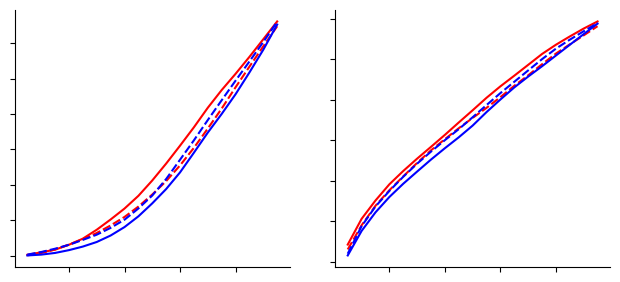

In [6]:
#Percentiles of each recording
quantiles = np.arange(0.05, 0.951, 0.05).round(2)

quantile_df = smile_df.groupby(key + ["signal", "u_cond"])["smile"].quantile(quantiles).reset_index()
#groupby().quantile() puts the percentile in an unnamed column (level_7, after the 7 grouping columns)
quantile_df = quantile_df.rename({"level_7": "percentile"}, axis=1)
quantile_df["percentile"] = (quantile_df["percentile"] * 100).round().astype(int)

#Readable names for the figure (the column names become the legend titles)
df_analysis = quantile_df.copy()
df_analysis["participant_condition"] = df_analysis["participant_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis["other_condition"] = df_analysis["other_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis = df_analysis.rename({"participant_condition": "participant condition", "other_condition": "other condition"}, axis=1)

#Plot
g = sns.relplot(x="percentile", y="smile"
            , aspect=1
            , height=3.5
            , hue="other condition"
            , style="participant condition"
            , col="signal"
            , col_order=["mouth", "eyes"]
            , data= df_analysis
            , kind="line"
            , ci=None
            , hue_order = ["increase", "decrease"]
            , style_order = ["increase", "decrease"]
            , palette= ["red", "blue"]
            , facet_kws={"sharey": False}
            )

#Titles and labels
g.axes_dict["eyes"].set_title("Eyes (AU06)")
g.axes_dict["mouth"].set_title("Mouth (MediaPipe smile)")
g.axes_dict["eyes"].set_ylabel("AU06 intensity (0-1)")
g.axes_dict["mouth"].set_ylabel("smile intensity (0-2)")
g.set_xlabels("percentile of the recording's distribution")

#Save with and without labels
plt.savefig("plots/smile_decomposition/quantile_profile_legend.pdf", bbox_inches='tight')
g._legend.remove()
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/smile_decomposition/quantile_profile.pdf", bbox_inches='tight')

For the mouth, the four conditions overlap at the lowest percentiles; when both partners' smiles are increased, the middle and upper parts of the distribution are shifted up (SS about 0.15 above SU and US between the 55th and 75th percentiles). For the eyes the shift is smaller and similar at all percentiles (about 0.02–0.03). This is compatible with more time spent smiling rather than stronger smiles, which is tested directly with the smile episodes below. (Descriptive only : no test per percentile.)

# Smile episodes: more often or more intense?
First 250 s of each recording, smoothed with a 0.5 s running median. A participant smiles when the smoothed signal is above their own P75 (pooled over their interactions).
Episodes shorter than 0.5 s are dropped and gaps shorter than 0.5 s are bridged. Recordings with less than 60 s of detected face are left out.

In [7]:
#Time series on a 250 s grid (missing frames = no face detected)
fps = 30
n_max = 250 * fps

ts_list = []
for keys, rec_df in smile_df.groupby(key + ["signal", "u_cond"]):
    #reindex puts every frame from 0 to 250 s in order; frames without a face (or after the end) become NaN
    rec_df = rec_df.set_index("frame").reindex(range(n_max))

    ts_df = pd.DataFrame({"frame": range(n_max), "smile": rec_df["smile"].values})
    #Running median over 0.5 s centred on each frame (needs at least 7 valid frames)
    ts_df["smooth"] = ts_df["smile"].rolling(int(0.5 * fps), center=True, min_periods=7).median()
    for name, value in zip(key + ["signal", "u_cond"], keys):
        ts_df[name] = value

    #Skip recordings with less than 60 s of face
    if ts_df["smile"].notna().sum() < 60 * fps:
        continue
    ts_list.append(ts_df)

ts_df = pd.concat(ts_list)

#Own threshold : P75 of each participant's smoothed signal over all their interactions
#(transform returns the value of the group on every row of the group)
ts_df["threshold"] = ts_df.groupby(["signal", "user_id"])["smooth"].transform(lambda x: x.quantile(0.75))

In [8]:
#Smile episodes and measures per recording
def get_episodes(smooth, threshold, min_len=15, max_gap=15):
    """
        Smile episodes : smoothed signal above threshold for at least min_len frames.
        Gaps shorter than max_gap frames are bridged.
    """
    #Frames above threshold (frames without a face count as not smiling)
    above = np.nan_to_num(smooth, nan=-1) > threshold

    #Start and end of each run of frames above threshold : +1 where a run starts, -1 just after it ends
    edges = np.diff(np.r_[0, above.astype(int), 0])
    starts = np.where(edges == 1)[0]
    ends = np.where(edges == -1)[0]

    #Merge runs separated by a short gap
    episodes = []
    for start, end in zip(starts, ends):
        if len(episodes) > 0 and start - episodes[-1][1] < max_gap:
            episodes[-1][1] = end
        else:
            episodes.append([start, end])

    #Drop the short episodes
    return [e for e in episodes if e[1] - e[0] >= min_len]


#Measures per recording
episodes_list = []
for keys, rec_df in ts_df.groupby(key + ["signal", "u_cond"]):
    smooth = rec_df["smooth"].values
    valid = rec_df["smile"].notna().values
    episodes = get_episodes(smooth, rec_df["threshold"].iloc[0])

    #True on every frame inside an episode
    smiling = np.zeros(len(smooth), bool)
    for start, end in episodes:
        smiling[start:end] = True

    #Time between the end of an episode and the start of the next one, only for gaps with data on every frame
    #(a stretch without data, e.g. a disconnection or a face not detected for a while, is not a time without smiling)
    gaps = [(episodes[i + 1][0] - episodes[i][1]) / fps for i in range(len(episodes) - 1)
            if not np.isnan(smooth[episodes[i][1]:episodes[i + 1][0]]).any()]

    episodes_list.append(dict(zip(key + ["signal", "u_cond"], keys)
                    , time_smiling = 100 * (smiling & valid).sum() / valid.sum()
                    , rate = len(episodes) / (valid.sum() / fps / 60)
                    , gap = np.median(gaps) if len(gaps) > 0 else np.nan
                    , peak = np.mean([np.nanmax(smooth[start:end]) for start, end in episodes]) if len(episodes) > 0 else np.nan
                    ))

episodes_df = pd.DataFrame(episodes_list)

#Table for R_scripts/smile_episodes_stats.R
episodes_df.to_csv("../data/face_data/smile_episodes_v3.csv", index=False)

`time_smiling` : % of the time spent smiling; `rate` : smile episodes per minute; `gap` : median time between two smiles (s; gaps containing frames without data are not counted); `peak` : mean maximum of the episodes.
The statistics of these measures are in `R_scripts/smile_episodes_stats.R`, on the table written here.

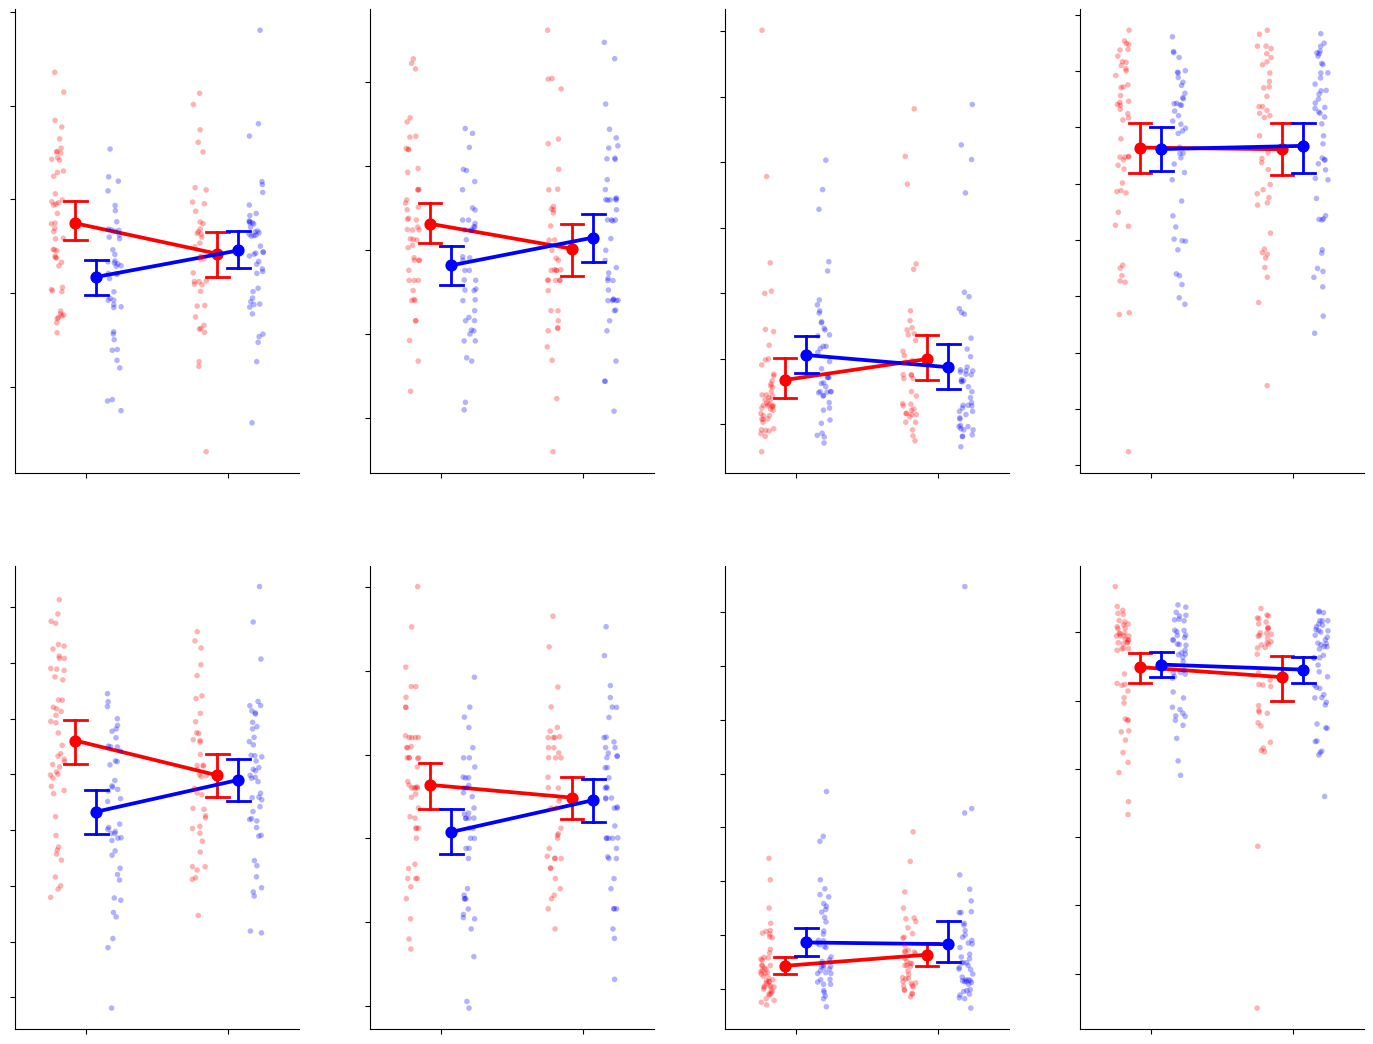

In [9]:
#Long table (melt) : one row per recording and measure, so each measure can be a column of the figure
df_analysis = episodes_df.melt(id_vars=key + ["signal", "u_cond"], value_vars=["time_smiling", "rate", "gap", "peak"], var_name="measure")

#Readable condition names for the figure
df_analysis["participant_condition"] = df_analysis["participant_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis["other_condition"] = df_analysis["other_condition"].replace({"S": "increase", "U": "decrease"})

#Plot
g = sns.catplot( x="participant_condition", y="value", units="user_id"
                    , height=6
                    , aspect=0.55
                    , data=df_analysis
                    , kind="point"
                    , capsize=.16
                    , hue="other_condition"
                    , row="signal"
                    , col="measure"
                    , row_order=["mouth", "eyes"]
                    , col_order=["time_smiling", "rate", "gap", "peak"]
                    , dodge= 0.15
                    , errwidth=2
                    , ci=95
                    , order=["increase", "decrease"]
                    , hue_order=["increase", "decrease"]
                    , palette= sns.color_palette(["red", "blue"])
                    , sharey=False
            )

# Add individual measure points (map_dataframe draws the stripplot in every panel of the grid)
g.map_dataframe(sns.stripplot, x="participant_condition", y="value"
                , hue="other_condition", dodge=True, size=4, alpha=0.3
                , legend=False
                , order=["increase", "decrease"]
                , hue_order=["increase", "decrease"]
                , palette= sns.color_palette(["red", "blue"])
                )

#Titles : g.axes_dict gives the panel of each (signal, measure) pair
measure_names = {"time_smiling": "time smiling (%)", "rate": "smiles per minute", "gap": "time between smiles (s)", "peak": "smile peak"}
signal_names = {"eyes": "Eyes (AU06)", "mouth": "Mouth (smile)"}
for (signal, measure), ax in g.axes_dict.items():
    ax.set_title(signal_names[signal] + "\n" + measure_names[measure], fontsize=13, pad=17)
    ax.set_ylabel(measure_names[measure], fontsize=12)
    ax.tick_params(labelsize=11)
g.set_xlabels("participant condition", fontsize=12)
g._legend.set_title("other condition")

#Legend on top of the panels, on one line, instead of on the right
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 0.99), ncol=2, frameon=False, fontsize=12, title_fontsize=12, columnspacing=1, handletextpad=0.4, borderpad=0)

#More space between the two rows for the titles and statistics; use the full width now that the legend is below
g.figure.subplots_adjust(hspace=0.2, wspace=0.25, right=0.98, bottom=0.07, top=0.92)

#Save with and without labels
plt.savefig("plots/smile_decomposition/smile_more_often_legend.pdf", bbox_inches='tight')
g._legend.remove()
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/smile_decomposition/smile_more_often.pdf", bbox_inches='tight')

SS participants smile more often, not more intensely (`R_scripts/smile_episodes_stats.R`, 177 recordings, participant × other condition interaction) :
* time smiling : mouth χ²(1) = 8.10, p = .004; eyes χ²(1) = 8.66, p = .003 (SS − SU : mouth +5.7, eyes +6.3 percentage points)
* smiles per minute : mouth χ²(1) = 6.52, p = .011; eyes χ²(1) = 5.31, p = .021 (SS − SU : about +1 smile per minute)
* time between smiles : no interaction (mouth χ²(1) = 2.65, p = .10; eyes χ²(1) = 0.80, p = .37), although SS − SU is shorter (mouth −0.76 s, p = .09; eyes −0.87 s, p = .023)
* peak : no interaction (mouth χ²(1) = 3.42, p = .064; eyes χ²(1) = 0.08, p = .77)

# Time course
Mean smile intensity in 25 s bins over the first 250 s (mean ± 68% CI, about ± 1 SEM, across recordings). Eyes recordings stored in several blocks are left out.
The overall effect is tested on the whole-recording means (# Smile level).

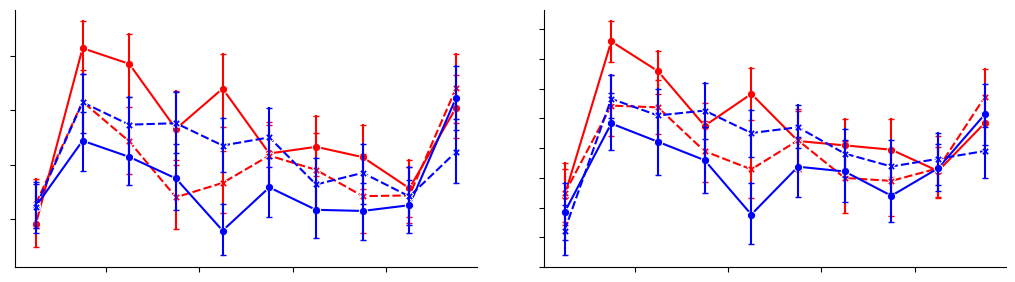

In [10]:
#Leave out eyes recordings stored in several blocks
time_df = ts_df.merge(blocks_df[key + ["signal", "contiguous"]], on=key + ["signal"], how="left")
#Mouth recordings have no block information : they are all contiguous
time_df["contiguous"] = time_df["contiguous"].fillna(True)

time_df = time_df.loc[time_df["contiguous"] == True]

#Mean smile in 25 s bins
#Bin number (frame // bin length) converted to the bin centre in seconds
time_df["time"] = (time_df["frame"] // (25 * fps)) * 25 + 12.5
window_df = time_df.groupby(key + ["signal", "u_cond", "time"])["smile"].mean().reset_index()

#Readable names for the figure (the column names become the legend titles)
df_analysis = window_df.copy()
df_analysis["participant_condition"] = df_analysis["participant_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis["other_condition"] = df_analysis["other_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis = df_analysis.rename({"participant_condition": "participant condition", "other_condition": "other condition"}, axis=1)

#Plot
g = sns.relplot(x="time", y="smile"
            , aspect=1.3
            , height=3.5
            , hue="other condition"
            , style="participant condition"
            , col="signal"
            , col_order=["mouth", "eyes"]
            , data= df_analysis
            , kind="line"
            , ci=68
            , err_style="bars"
            , err_kws={"capsize": 2}
            , markers=True
            , dashes=True
            , hue_order = ["increase", "decrease"]
            , style_order = ["increase", "decrease"]
            , palette= ["red", "blue"]
            , facet_kws={"sharey": False}
            )

#Titles and labels
g.axes_dict["eyes"].set_title("Eyes (AU06)")
g.axes_dict["mouth"].set_title("Mouth (MediaPipe smile)")
g.axes_dict["eyes"].set_ylabel("AU06 intensity")
g.axes_dict["mouth"].set_ylabel("smile intensity")
g.set_xlabels("time in the interaction (s, centre of the 25 s bin)")

#Legend on top of the panels, on one line, instead of on the right
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 1.03), ncol=6, frameon=False, columnspacing=0.8, handlelength=1.6, handletextpad=0.4, borderpad=0)
g.figure.subplots_adjust(right=0.97)

#Save with and without labels
plt.savefig("plots/smile_decomposition/time_course_legend.pdf", bbox_inches='tight')
g._legend.remove()
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/smile_decomposition/time_course.pdf", bbox_inches='tight')

All conditions start at the same level. SS rises above the other conditions after about 25 s and the difference fades after about 125 s.

# Raster
One row per recording: smile level as the participant's own percentile (1 s bins), rows sorted by time smiling. Bright = above the participant's median; the smile threshold is P75.

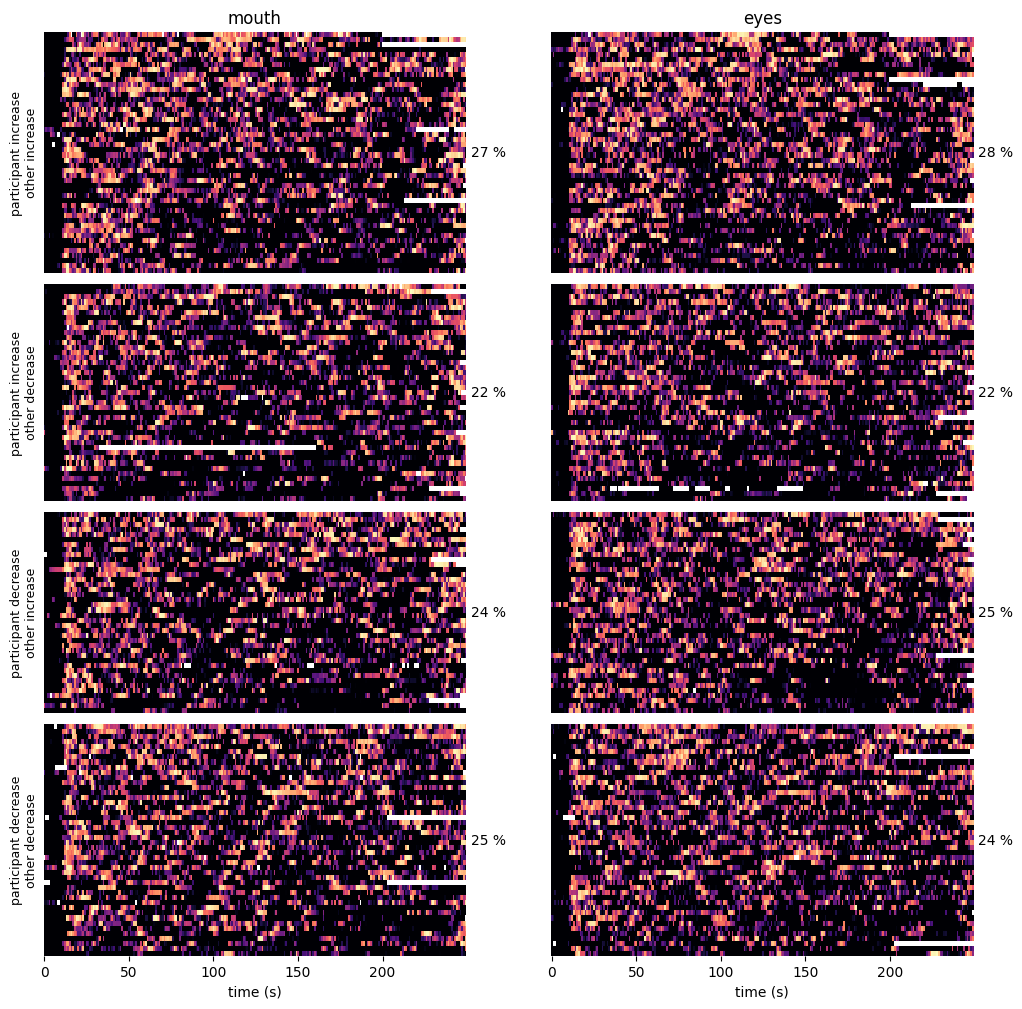

In [11]:
#Smile level as the participant's own percentile, in 1 s bins
raster_df = ts_df.copy()
#Rank of each frame within the participant's own frames (0-1), so people with different baselines are comparable
raster_df["percentile"] = raster_df.groupby(["signal", "user_id"])["smooth"].rank(pct=True)
raster_df["second"] = raster_df["frame"] // fps
raster_df = raster_df.groupby(key + ["signal", "u_cond", "second"]).mean(numeric_only=True).reset_index()
raster_df = raster_df.merge(episodes_df[key + ["signal", "time_smiling"]], on=key + ["signal"])

#One heatmap per signal and condition, rows sorted by time smiling
conditions = ["SS", "SU", "US", "UU"]
names = {"S": "increase", "U": "decrease"}
n_rows = [len(episodes_df.loc[episodes_df["u_cond"] == cond].groupby(key)) for cond in conditions]

#Panel heights proportional to the number of recordings in each condition
fig, axes = plt.subplots(4, 2, figsize=(12, 12), gridspec_kw={"height_ratios": n_rows, "hspace": 0.05})
for j, signal in enumerate(["mouth", "eyes"]):
    for i, cond in enumerate(conditions):
        df_analysis = raster_df.loc[(raster_df["signal"] == signal) & (raster_df["u_cond"] == cond)]
        #One row per recording, one column per second; time_smiling in the index so rows can be sorted by it
        df_analysis = df_analysis.pivot_table(index=["time_smiling", "user_id", "other_id"], columns="second", values="percentile")
        df_analysis = df_analysis.sort_index(ascending=False)

        ax = axes[i, j]
        #Colour scale from the participant's median (black) to their maximum (white); NaN = no data
        sns.heatmap(df_analysis, ax=ax, cmap="magma", vmin=0.5, vmax=1, cbar=False, xticklabels=50, yticklabels=False)
        ax.set(xlabel=None, ylabel=None)
        if j == 0:
            ax.set_ylabel("participant " + names[cond[0]] + "\nother " + names[cond[1]], fontsize=9)
        ax.text(1.01, 0.5, str(round(np.mean(df_analysis.index.get_level_values("time_smiling")))) + " %", transform=ax.transAxes, va="center")
        if i == 0:
            ax.set_title(signal)
        if i < 3:
            ax.set_xticks([])
axes[3, 0].set_xlabel("time (s)")
axes[3, 1].set_xlabel("time (s)")

#Save
plt.savefig("plots/smile_decomposition/smile_raster.pdf", bbox_inches='tight')

# Conclusions
* The smile effect is mainly SS > SU (and SS > US), for both the eyes and the mouth.
* For the mouth, the floor does not move and the middle and upper part of the distribution shifts up; for the eyes the shift is small at all percentiles.
* People smile more often (more time smiling, more smiles per minute), not more intensely; the gaps between smiles do not differ significantly.
* The effect is between 25 and 125 s, like the pitch effect (`audio_analysis/pitch_std_decomposition.ipynb`).